# Home Assignment 2 — CS5720 Neural Networks and Deep Learning
**Student:** Palash Palit

## How to run this notebook
1. **Runtime → Change runtime type → T4 GPU → Save.** (Q1 and Q2 train much faster on a GPU.)
2. **Runtime → Run all.**
3. Wait for everything to finish (about 10–15 minutes on a GPU).
4. Scroll to the **last cell** and copy its whole output. That block has all the numbers needed for the assignment document.

Q1 and Q2 train neural networks. Q3–Q5 run in a few seconds.

In [1]:
# Setup: imports and GPU check
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", bool(gpus), gpus)
if not gpus:
    print("No GPU found. It will still work, but slower. Use Runtime -> Change runtime type -> T4 GPU.")

TensorFlow version: 2.20.0
GPU available: True [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Q1: Implementing an RNN for Text Generation
A character-level LSTM learns to predict the next character of Shakespeare's text, then generates new text at three temperatures.

In [2]:
# 1. Load the text dataset (Tiny Shakespeare, public domain)
path = tf.keras.utils.get_file(
    "shakespeare.txt",
    "https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt")
with open(path, "r", encoding="utf-8") as f:
    text = f.read()
print("Total characters in corpus:", len(text))

# 2. Convert text into a sequence of characters (integer-encoded)
vocab = sorted(set(text))
vocab_size = len(vocab)
print("Unique characters (vocabulary size):", vocab_size)

char_to_idx = {ch: i for i, ch in enumerate(vocab)}
idx_to_char = {i: ch for i, ch in enumerate(vocab)}
encoded_text = np.array([char_to_idx[ch] for ch in text])

# Build (input_sequence -> next_character) training pairs
SEQ_LENGTH = 100
char_dataset = tf.data.Dataset.from_tensor_slices(encoded_text)
sequences = char_dataset.batch(SEQ_LENGTH + 1, drop_remainder=True)

def split_input_target(chunk):
    return chunk[:-1], chunk[1:]   # input = all but last char, target = shifted by one

dataset = sequences.map(split_input_target)
BATCH_SIZE = 64
BUFFER_SIZE = 10000
dataset = dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE, drop_remainder=True)

1115394/1115394 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total characters in corpus: 1115394
Unique characters (vocabulary size): 65


In [3]:
# 3. Define an RNN model using LSTM layers to predict the next character
EMBEDDING_DIM = 256
RNN_UNITS = 512

def build_model(vocab_size, embedding_dim, rnn_units, batch_size):
    model = tf.keras.Sequential([
        tf.keras.Input(batch_shape=(batch_size, None)),
        tf.keras.layers.Embedding(vocab_size, embedding_dim),
        tf.keras.layers.LSTM(rnn_units, return_sequences=True, stateful=True,
                             recurrent_initializer="glorot_uniform"),
        tf.keras.layers.Dense(vocab_size),
    ])
    return model

model = build_model(vocab_size, EMBEDDING_DIM, RNN_UNITS, BATCH_SIZE)
model.summary()

def loss_fn(labels, logits):
    return tf.keras.losses.sparse_categorical_crossentropy(labels, logits, from_logits=True)

model.compile(optimizer="adam", loss=loss_fn)

# 4. Train the model
EPOCHS = 5
q1_history = model.fit(dataset, epochs=EPOCHS)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (64, None, 256)        │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (64, None, 512)        │     1,574,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (64, None, 65)         │        33,345 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,624,897 (6.20 MB)

 Trainable params: 1,624,897 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
172/172 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - loss: 2.4614
Epoch 2/5
172/172 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - loss: 1.9021
Epoch 3/5
172/172 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 1.7146
Epoch 4/5
172/172 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - loss: 1.6070
Epoch 5/5
172/172 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - loss: 1.5357


In [4]:
# 5. Generate text by sampling characters one at a time
# Rebuild with batch_size=1 for generation and copy the trained weights
gen_model = build_model(vocab_size, EMBEDDING_DIM, RNN_UNITS, batch_size=1)
gen_model.set_weights(model.get_weights())

def generate_text(model, start_string, num_generate=300, temperature=1.0):
    input_eval = tf.expand_dims([char_to_idx[s] for s in start_string], 0)
    text_generated = []
    for layer in model.layers:            # clear the LSTM's memory before generating
        if hasattr(layer, "reset_states"):
            layer.reset_states()
    for _ in range(num_generate):
        predictions = tf.squeeze(model(input_eval), 0)
        predictions = predictions / temperature          # temperature scaling
        predicted_id = tf.random.categorical(predictions, num_samples=1)[-1, 0].numpy()
        input_eval = tf.expand_dims([predicted_id], 0)
        text_generated.append(idx_to_char[predicted_id])
    return start_string + "".join(text_generated)

q1_samples = {}
for temp in [0.5, 1.0, 1.5]:
    q1_samples[temp] = generate_text(gen_model, start_string="ROMEO: ", temperature=temp)
    print("=" * 60)
    print(f"Temperature = {temp}")
    print("=" * 60)
    print(q1_samples[temp])
    print()

Temperature = 0.5
ROMEO: fair,
Come and so, and we be exemies of doother.

DUKE VINCENTIO:
Good my lord,
Where is eyes are to be strength and then a lobler:
His commend in the very death: they father then
As it we was a shall for this sould and the love and ender here.

TRANIO:
Made your grace to the foes and to the life co

Temperature = 1.0
ROMEO: this, thyselverent,
And three, many sent four home,
That went, yet so a kinds of give to revenge.
She lits Angul ant!

MONTELIO:
What he hanged for the old bend thy weateners.

LUCENTIO:
Well tell me,
O eart on hence: that, my broarth for gentle.
O, the does in things must a choses and that deas
Mis

Temperature = 1.5
ROMEO: we?
GROF:
Me thy equite.
ViLYevewe!

MOMTAWBUMUS:
Ho; my hoursaning anirs. give's. Gialmal, yaur-'que
Shopeomver sifelning not so elded wetkshy:
My bassmin-matervave by revel,
That plowery? O'W
Wh DUKN VIWPY Alsh it; at thission; I'rven you; sa! RGCENDIIU:
Forlays,
And pity let'e
Off the unfor am--w



## Q2: Sentiment Classification Using RNN
An LSTM classifies IMDB movie reviews as positive or negative. Evaluated with a confusion matrix and classification report.

In [5]:
# 1. Load the IMDB sentiment dataset
VOCAB_SIZE = 10000
MAX_LEN = 200
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.imdb.load_data(num_words=VOCAB_SIZE)
print("Training samples:", len(x_train))
print("Test samples:", len(x_test))

# 2. Preprocess: reviews are already tokenized as word indices; pad to a fixed length
x_train = tf.keras.preprocessing.sequence.pad_sequences(x_train, maxlen=MAX_LEN)
x_test = tf.keras.preprocessing.sequence.pad_sequences(x_test, maxlen=MAX_LEN)

# 3. Build and train an LSTM-based sentiment classifier
q2_model = tf.keras.Sequential([
    tf.keras.Input(shape=(MAX_LEN,)),
    tf.keras.layers.Embedding(VOCAB_SIZE, 128),
    tf.keras.layers.LSTM(64, dropout=0.2, recurrent_dropout=0.2),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
q2_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
q2_model.summary()

q2_history = q2_model.fit(x_train, y_train, validation_split=0.2,
                          epochs=5, batch_size=128, verbose=2)

q2_test_loss, q2_test_acc = q2_model.evaluate(x_test, y_test, verbose=0)
print(f"\nTest Accuracy: {q2_test_acc:.4f}")
print(f"Test Loss: {q2_test_loss:.4f}")

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 25000
Test samples: 25000


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329,473 (5.07 MB)

 Trainable params: 1,329,473 (5.07 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
157/157 - 117s - 748ms/step - accuracy: 0.7470 - loss: 0.5093 - val_accuracy: 0.8182 - val_loss: 0.4025
Epoch 2/5
157/157 - 110s - 698ms/step - accuracy: 0.8587 - loss: 0.3444 - val_accuracy: 0.7926 - val_loss: 0.4577
Epoch 3/5
157/157 - 113s - 718ms/step - accuracy: 0.8795 - loss: 0.3014 - val_accuracy: 0.8158 - val_loss: 0.4154
Epoch 4/5
157/157 - 110s - 701ms/step - accuracy: 0.8968 - loss: 0.2618 - val_accuracy: 0.8440 - val_loss: 0.4048
Epoch 5/5
157/157 - 110s - 703ms/step - accuracy: 0.9186 - loss: 0.2152 - val_accuracy: 0.8448 - val_loss: 0.3892

Test Accuracy: 0.8458
Test Loss: 0.3882


Confusion Matrix:
[[10404  2096]
 [ 1760 10740]]

Classification Report:
              precision    recall  f1-score   support

    Negative       0.86      0.83      0.84     12500
    Positive       0.84      0.86      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



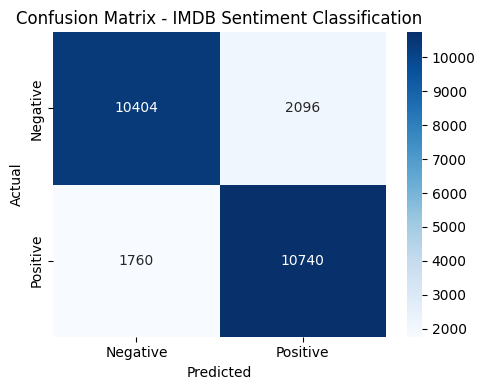

In [6]:
# 4. Confusion matrix and classification report
y_pred = (q2_model.predict(x_test, verbose=0) > 0.5).astype(int).flatten()
q2_cm = confusion_matrix(y_test, y_pred)
q2_report = classification_report(y_test, y_pred, target_names=["Negative", "Positive"])
print("Confusion Matrix:")
print(q2_cm)
print("\nClassification Report:")
print(q2_report)

plt.figure(figsize=(5, 4))
sns.heatmap(q2_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion Matrix - IMDB Sentiment Classification")
plt.tight_layout()
plt.savefig("imdb_confusion_matrix.png", dpi=150)
plt.show()

## Q3: Convolution Operations with Different Parameters

In [7]:
input_matrix = np.array([[1, 2, 3, 4, 5],
                         [6, 7, 8, 9, 10],
                         [11, 12, 13, 14, 15],
                         [16, 17, 18, 19, 20],
                         [21, 22, 23, 24, 25]], dtype=np.float32)
kernel = np.array([[0, 1, 0],
                   [1, -4, 1],
                   [0, 1, 0]], dtype=np.float32)

# TensorFlow conv2d needs input (batch, height, width, channels) and kernel (h, w, in_ch, out_ch)
input_tensor = input_matrix.reshape(1, 5, 5, 1)
kernel_tensor = kernel.reshape(3, 3, 1, 1)

def run_convolution(stride, padding):
    result = tf.nn.conv2d(input_tensor, kernel_tensor, strides=[1, stride, stride, 1], padding=padding)
    return result.numpy().reshape(result.shape[1], result.shape[2])

for stride, padding in [(1, "VALID"), (1, "SAME"), (2, "VALID"), (2, "SAME")]:
    out = run_convolution(stride, padding)
    print(f"Stride = {stride}, Padding = '{padding}'  ->  output shape {out.shape}")
    print(out, "\n")

Stride = 1, Padding = 'VALID'  ->  output shape (3, 3)
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]] 

Stride = 1, Padding = 'SAME'  ->  output shape (5, 5)
[[  4.   3.   2.   1.  -6.]
 [ -5.   0.   0.   0. -11.]
 [-10.   0.   0.   0. -16.]
 [-15.   0.   0.   0. -21.]
 [-46. -27. -28. -29. -56.]] 

Stride = 2, Padding = 'VALID'  ->  output shape (2, 2)
[[0. 0.]
 [0. 0.]] 

Stride = 2, Padding = 'SAME'  ->  output shape (3, 3)
[[  4.   2.  -6.]
 [-10.   0. -16.]
 [-46. -28. -56.]] 



## Q4: CNN Feature Extraction with Filters and Pooling
### Task 1: Edge Detection Using Sobel Filter

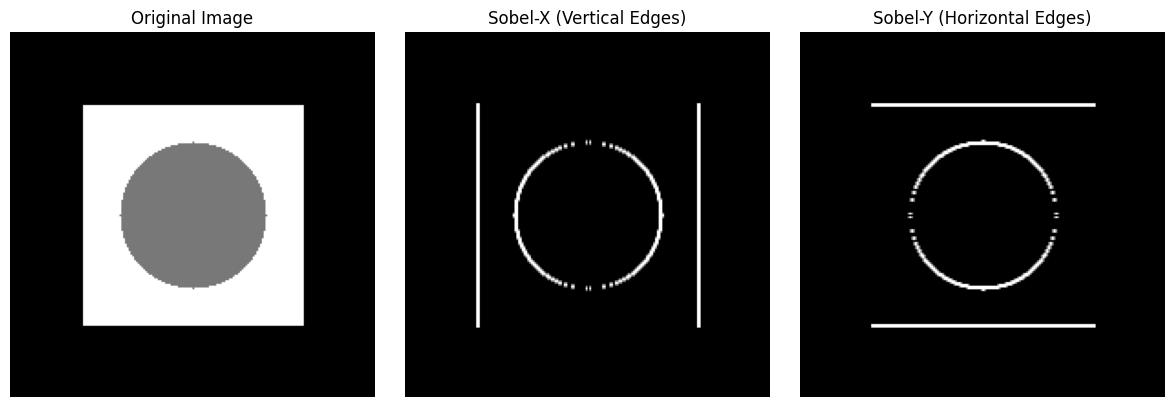

In [8]:
# Synthetic grayscale image with clear edges (a square with a circle inside)
image = np.zeros((200, 200), dtype=np.uint8)
cv2.rectangle(image, (40, 40), (160, 160), 255, -1)
cv2.circle(image, (100, 100), 40, 120, -1)

sobel_x_kernel = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
sobel_y_kernel = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32)

sobel_x = cv2.filter2D(image, cv2.CV_64F, sobel_x_kernel)
sobel_y = cv2.filter2D(image, cv2.CV_64F, sobel_y_kernel)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, title in zip(axes,
                          [image, cv2.convertScaleAbs(sobel_x), cv2.convertScaleAbs(sobel_y)],
                          ["Original Image", "Sobel-X (Vertical Edges)", "Sobel-Y (Horizontal Edges)"]):
    ax.imshow(img, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout()
plt.savefig("sobel_edge_detection.png", dpi=150)
plt.show()

### Task 2: Max Pooling and Average Pooling

In [9]:
np.random.seed(42)
pool_input = np.random.randint(0, 10, size=(4, 4)).astype(np.float32)
pool_tensor = pool_input.reshape(1, 4, 4, 1)

max_pooled = tf.keras.layers.MaxPooling2D(pool_size=(2, 2))(pool_tensor).numpy().reshape(2, 2)
avg_pooled = tf.keras.layers.AveragePooling2D(pool_size=(2, 2))(pool_tensor).numpy().reshape(2, 2)

print("Original 4x4 Matrix:\n", pool_input)
print("\nMax Pooled (2x2):\n", max_pooled)
print("\nAverage Pooled (2x2):\n", avg_pooled)

Original 4x4 Matrix:
 [[6. 3. 7. 4.]
 [6. 9. 2. 6.]
 [7. 4. 3. 7.]
 [7. 2. 5. 4.]]

Max Pooled (2x2):
 [[9. 7.]
 [7. 7.]]

Average Pooled (2x2):
 [[6.   4.75]
 [5.   4.75]]


## Q5: Implementing and Comparing CNN Architectures
### Task 1: AlexNet

In [10]:
def build_alexnet(input_shape=(227, 227, 3), num_classes=10):
    return models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(96, (11, 11), strides=4, activation="relu"),
        layers.MaxPooling2D((3, 3), strides=2),
        layers.Conv2D(256, (5, 5), activation="relu", padding="same"),
        layers.MaxPooling2D((3, 3), strides=2),
        layers.Conv2D(384, (3, 3), activation="relu", padding="same"),
        layers.Conv2D(384, (3, 3), activation="relu", padding="same"),
        layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((3, 3), strides=2),
        layers.Flatten(),
        layers.Dense(4096, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(4096, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation="softmax"),
    ])

alexnet = build_alexnet()
alexnet.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 55, 55, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 27, 27, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 27, 27, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 13, 13, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4096)           │    37,752,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │        40,970 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,322,314 (222.48 MB)

 Trainable params: 58,322,314 (222.48 MB)

 Non-trainable params: 0 (0.00 B)

### Task 2: Residual Block and ResNet

In [11]:
def residual_block(input_tensor, filters):
    x = layers.Conv2D(filters, (3, 3), padding="same", activation="relu")(input_tensor)
    x = layers.Conv2D(filters, (3, 3), padding="same")(x)
    x = layers.Add()([x, input_tensor])      # skip connection: add the block's input back
    return layers.Activation("relu")(x)

def build_resnet(input_shape=(224, 224, 3), num_classes=10):
    inputs = layers.Input(shape=input_shape)
    x = layers.Conv2D(64, (7, 7), strides=2, padding="same", activation="relu")(inputs)
    x = residual_block(x, 64)
    x = residual_block(x, 64)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return models.Model(inputs, outputs, name="simple_resnet")

resnet = build_resnet()
resnet.summary()

Model: "simple_resnet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 112, 112,  │      9,472 │ input_layer_4[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 112, 112,  │     36,928 │ conv2d_5[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 112, 112,  │     36,928 │ conv2d_6[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 112, 112,  │          0 │ conv2d_7[0][0],   │
│                     │ 64)               │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 112, 112,  │     36,928 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 112, 112,  │     36,928 │ conv2d_8[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 112, 112,  │          0 │ conv2d_9[0][0],   │
│                     │ 64)               │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 112, 112,  │          0 │ add_1[0][0]       │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 802816)    │          0 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 128)       │ 102,760,5… │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 10)        │      1,290 │ dense_6[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 102,919,050 (392.61 MB)

 Trainable params: 102,919,050 (392.61 MB)

 Non-trainable params: 0 (0.00 B)

## Results Summary
**Copy the entire output of the cell below and paste it back to Claude** so the assignment document can be updated with your real results.

In [12]:
print("=" * 70)
print("HOME ASSIGNMENT 2 - RESULTS SUMMARY (Palash Palit)")
print("=" * 70)
print("TensorFlow", tf.__version__, "| GPU:", bool(tf.config.list_physical_devices("GPU")))

print("\n--- Q1: Text generation (full Tiny Shakespeare corpus) ---")
print("Corpus characters:", len(text), "| vocab size:", vocab_size)
for i, loss in enumerate(q1_history.history["loss"], 1):
    print(f"Epoch {i}/{len(q1_history.history['loss'])}  loss: {loss:.4f}")
for temp, sample in q1_samples.items():
    print(f"\n[Temperature {temp}]")
    print(sample)

print("\n--- Q2: IMDB sentiment classification (full 25k/25k dataset) ---")
h = q2_history.history
for i in range(len(h["accuracy"])):
    print(f"Epoch {i+1}/{len(h['accuracy'])}  accuracy: {h['accuracy'][i]:.4f}  loss: {h['loss'][i]:.4f}"
          f"  val_accuracy: {h['val_accuracy'][i]:.4f}  val_loss: {h['val_loss'][i]:.4f}")
print(f"Test Accuracy: {q2_test_acc:.4f}   Test Loss: {q2_test_loss:.4f}")
print("Confusion Matrix:")
print(q2_cm)
print("Classification Report:")
print(q2_report)
print("=" * 70)

HOME ASSIGNMENT 2 - RESULTS SUMMARY (Palash Palit)
TensorFlow 2.20.0 | GPU: True

--- Q1: Text generation (full Tiny Shakespeare corpus) ---
Corpus characters: 1115394 | vocab size: 65
Epoch 1/5  loss: 2.4614
Epoch 2/5  loss: 1.9021
Epoch 3/5  loss: 1.7146
Epoch 4/5  loss: 1.6070
Epoch 5/5  loss: 1.5357

[Temperature 0.5]
ROMEO: fair,
Come and so, and we be exemies of doother.

DUKE VINCENTIO:
Good my lord,
Where is eyes are to be strength and then a lobler:
His commend in the very death: they father then
As it we was a shall for this sould and the love and ender here.

TRANIO:
Made your grace to the foes and to the life co

[Temperature 1.0]
ROMEO: this, thyselverent,
And three, many sent four home,
That went, yet so a kinds of give to revenge.
She lits Angul ant!

MONTELIO:
What he hanged for the old bend thy weateners.

LUCENTIO:
Well tell me,
O eart on hence: that, my broarth for gentle.
O, the does in things must a choses and that deas
Mis

[Temperature 1.5]
ROMEO: we?
GROF:
Me th